In [2]:
!pip install -q --no-deps facenet-pytorch
!pip install -q mediapipe

import os

for root, dirs, files in os.walk('/kaggle/input'):
    if 'smile' in dirs or 'non_smile' in dirs:
        print("Found dataset root:", root)
        for d in dirs:
            print(f" -> {d}: {len(os.listdir(os.path.join(root, d)))} files")

Found dataset root: /kaggle/input/datasets/talhasar/genki4k/kaggle-genki4k
 -> non_smile: 1838 files
 -> smile: 2162 files


I0000 00:00:1794856129.452661    3397 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
W0000 00:00:1794856131.050030    3480 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794856131.064032    3485 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794856131.086695    3485 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Processing smile:   0%|          | 0/2162 [00:00<?, ?it/s]

Processing non_smile:   0%|          | 0/1838 [00:00<?, ?it/s]


Preprocessing Summary: {'aligned': 3966, 'center_crop': 34}


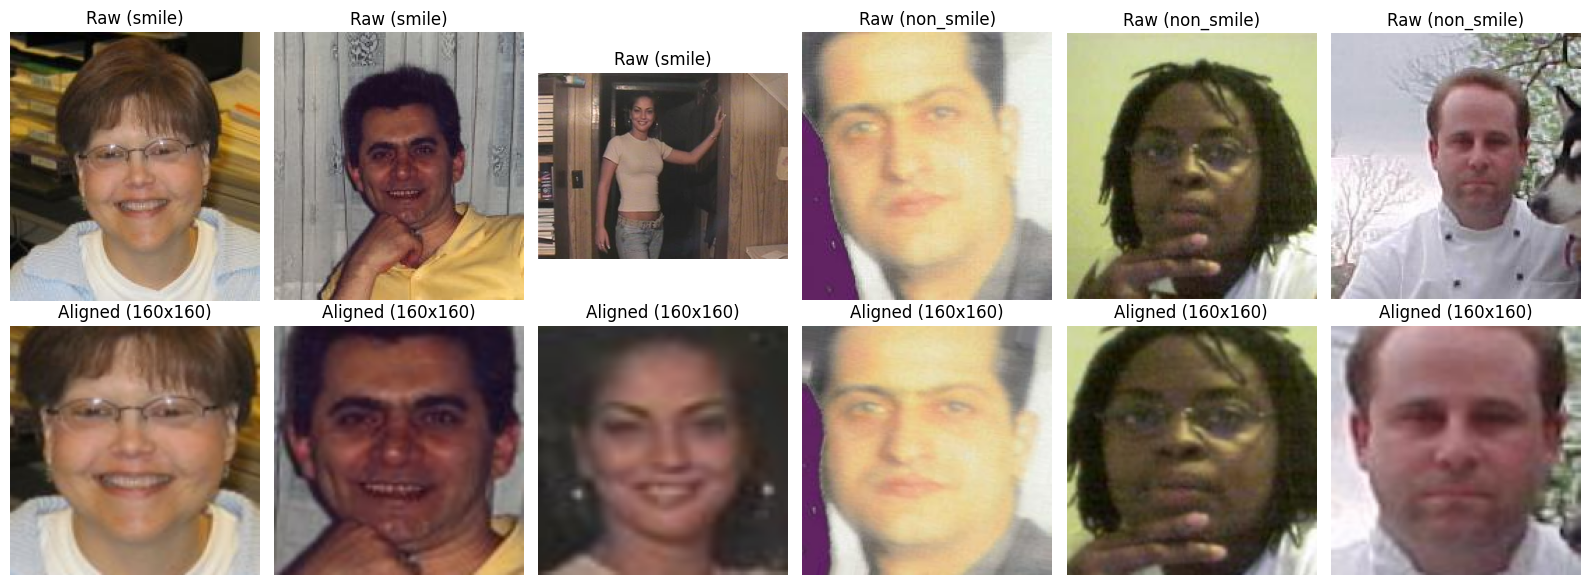

In [3]:
import os
import urllib.request
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

# 1. Define input/output paths and download official MediaPipe FaceLandmarker model
RAW_DATA_DIR = "/kaggle/input/datasets/talhasar/genki4k/kaggle-genki4k"
ALIGNED_DATA_DIR = "/kaggle/working/aligned_genki4k"
MODEL_ASSET_PATH = "/kaggle/working/face_landmarker.task"
IMG_SIZE = 160  # Standard input resolution for InceptionResNetV1

if not os.path.exists(MODEL_ASSET_PATH):
    url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    urllib.request.urlretrieve(url, MODEL_ASSET_PATH)

# 2. Initialize MediaPipe FaceLandmarker using the Tasks API
base_options = python.BaseOptions(model_asset_path=MODEL_ASSET_PATH)
options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    output_face_blendshapes=False,
    output_facial_transformation_matrixes=False,
    num_faces=1,
    min_face_detection_confidence=0.35,
    min_face_presence_confidence=0.35
)
landmarker = vision.FaceLandmarker.create_from_options(options)

def align_and_crop_face(image_bgr, output_size=160, margin_ratio=0.20):
    """
    Detects face landmarks via MediaPipe FaceLandmarker, performs eye-based
    affine alignment, and crops the aligned face region with padding.
    """
    h, w, _ = image_bgr.shape
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=image_rgb)
    
    # Detect 478 facial landmarks
    detection_result = landmarker.detect(mp_image)
    
    if detection_result.face_landmarks:
        landmarks = detection_result.face_landmarks[0]
        pts = np.array([[lm.x * w, lm.y * h] for lm in landmarks], dtype=np.float32)
        
        # Compute center coordinates for right and left eyes using inner/outer corners
        right_eye = np.mean([pts[33], pts[133]], axis=0)
        left_eye = np.mean([pts[362], pts[263]], axis=0)
        
        # Calculate roll angle and midpoint between eyes
        dy = left_eye[1] - right_eye[1]
        dx = left_eye[0] - right_eye[0]
        angle = np.degrees(np.arctan2(dy, dx))
        eyes_center = ((right_eye[0] + left_eye[0]) / 2.0, (right_eye[1] + left_eye[1]) / 2.0)
        
        # Apply affine rotation matrix to horizontally align the face
        rot_mat = cv2.getRotationMatrix2D(eyes_center, angle, scale=1.0)
        aligned_img = cv2.warpAffine(
            image_bgr, rot_mat, (w, h),
            flags=cv2.INTER_CUBIC,
            borderMode=cv2.BORDER_REPLICATE
        )
        
        # Project landmarks into the rotated coordinate space
        ones = np.ones((pts.shape[0], 1), dtype=np.float32)
        pts_homogeneous = np.hstack([pts, ones])
        aligned_pts = pts_homogeneous @ rot_mat.T
        
        # Compute bounding box around aligned landmarks with standard margin
        x_min, y_min = np.min(aligned_pts, axis=0)
        x_max, y_max = np.max(aligned_pts, axis=0)
        
        box_w = x_max - x_min
        box_h = y_max - y_min
        pad_x = box_w * margin_ratio
        pad_y = box_h * margin_ratio
        
        x1 = max(0, int(x_min - pad_x))
        y1 = max(0, int(y_min - pad_y))
        x2 = min(w, int(x_max + pad_x))
        y2 = min(h, int(y_max + pad_y))
        
        cropped = aligned_img[y1:y2, x1:x2]
        if cropped.size > 0:
            return cv2.resize(cropped, (output_size, output_size)), "aligned"

    # Fallback: Center square crop if landmarks are not detected
    min_dim = min(h, w)
    start_x = (w - min_dim) // 2
    start_y = (h - min_dim) // 2
    cropped = image_bgr[start_y:start_y+min_dim, start_x:start_x+min_dim]
    return cv2.resize(cropped, (output_size, output_size)), "center_crop"

# 3. Process all 4000 images and save aligned crops to working directory
stats = {"aligned": 0, "center_crop": 0}
sample_pairs = []

for label in ["smile", "non_smile"]:
    in_dir = os.path.join(RAW_DATA_DIR, label)
    out_dir = os.path.join(ALIGNED_DATA_DIR, label)
    os.makedirs(out_dir, exist_ok=True)
    
    files = sorted(os.listdir(in_dir))
    for idx, fname in enumerate(tqdm(files, desc=f"Processing {label}")):
        img_path = os.path.join(in_dir, fname)
        img = cv2.imread(img_path)
        if img is None:
            continue
            
        processed_img, method = align_and_crop_face(img, output_size=IMG_SIZE)
        stats[method] += 1
        
        out_path = os.path.join(out_dir, fname)
        cv2.imwrite(out_path, processed_img)
        
        # Store first 3 samples per class for visual inspection
        if idx < 3:
            sample_pairs.append((
                label,
                cv2.cvtColor(img, cv2.COLOR_BGR2RGB),
                cv2.cvtColor(processed_img, cv2.COLOR_BGR2RGB)
            ))

print("\nPreprocessing Summary:", stats)

# 4. Plot and save before/after face alignment comparison grid
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for i, (lbl, orig, aligned) in enumerate(sample_pairs):
    axes[0, i].imshow(orig)
    axes[0, i].set_title(f"Raw ({lbl})")
    axes[0, i].axis("off")
    
    axes[1, i].imshow(aligned)
    axes[1, i].set_title(f"Aligned ({IMG_SIZE}x{IMG_SIZE})")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/alignment_comparison.png", dpi=150)
plt.show()

In [4]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split

# 1. Collect all aligned image paths and binary labels (1: smile, 0: non_smile)
ALIGNED_DATA_DIR = "/kaggle/working/aligned_genki4k"
filepaths = []
labels = []

for label_name, label_idx in [("non_smile", 0), ("smile", 1)]:
    folder = os.path.join(ALIGNED_DATA_DIR, label_name)
    for fname in sorted(os.listdir(folder)):
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            filepaths.append(os.path.join(folder, fname))
            labels.append(label_idx)

# 2. Stratified 70% Train / 10% Validation / 20% Test split
X_train, X_temp, y_train, y_temp = train_test_split(
    filepaths, labels, test_size=0.30, random_state=42, stratify=labels
)

# Split the remaining 30% into 10% Validation (1/3 of 30%) and 20% Test (2/3 of 30%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=(2.0 / 3.0), random_state=42, stratify=y_temp
)

print(f"Dataset Split -> Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

# Compute positive class weight on training set to handle class imbalance
num_neg_train = y_train.count(0)
num_pos_train = y_train.count(1)
pos_weight_value = num_neg_train / num_pos_train
print(f"Train Class Balance -> Non-Smile: {num_neg_train}, Smile: {num_pos_train} | pos_weight: {pos_weight_value:.4f}")

# 3. Define Transforms: On-the-fly augmentation ONLY for training set
# Note: facenet-pytorch InceptionResNetV1 expects pixel values normalized to [-1, 1] via (x - 0.5) / 0.5
train_transforms = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.2))], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.10))
])

eval_transforms = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# 4. Custom PyTorch Dataset
class SmileDataset(Dataset):
    def __init__(self, image_paths, targets, transform=None):
        self.image_paths = image_paths
        self.targets = targets
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        label = torch.tensor(self.targets[idx], dtype=torch.float32)
        return img, label

# 5. Instantiate Datasets and DataLoaders
BATCH_SIZE = 32

train_dataset = SmileDataset(X_train, y_train, transform=train_transforms)
val_dataset = SmileDataset(X_val, y_val, transform=eval_transforms)
test_dataset = SmileDataset(X_test, y_test, transform=eval_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print("DataLoaders initialized successfully.")

Dataset Split -> Train: 2800 | Val: 400 | Test: 800
Train Class Balance -> Non-Smile: 1287, Smile: 1513 | pos_weight: 0.8506
DataLoaders initialized successfully.


In [5]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Set device (GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

# 2. Standalone InceptionResNetV1 Architecture (Compatible with official VGGFace2 weights)
class BasicConv2d(nn.Module):
    def __init__(self, in_planes, out_planes, kernel_size, stride, padding=0):
        super().__init__()
        self.conv = nn.Conv2d(in_planes, out_planes, kernel_size=kernel_size, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_planes, eps=0.001, momentum=0.1, affine=True)
        self.relu = nn.ReLU(inplace=False)

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))

class Block35(nn.Module):
    def __init__(self, scale=1.0):
        super().__init__()
        self.scale = scale
        self.branch0 = BasicConv2d(256, 32, kernel_size=1, stride=1)
        self.branch1 = nn.Sequential(
            BasicConv2d(256, 32, kernel_size=1, stride=1),
            BasicConv2d(32, 32, kernel_size=3, stride=1, padding=1)
        )
        self.branch2 = nn.Sequential(
            BasicConv2d(256, 32, kernel_size=1, stride=1),
            BasicConv2d(32, 32, kernel_size=3, stride=1, padding=1),
            BasicConv2d(32, 32, kernel_size=3, stride=1, padding=1)
        )
        self.conv2d = nn.Conv2d(96, 256, kernel_size=1, stride=1)
        self.relu = nn.ReLU(inplace=False)

    def forward(self, x):
        out = torch.cat((self.branch0(x), self.branch1(x), self.branch2(x)), 1)
        out = self.conv2d(out)
        return self.relu(out * self.scale + x)

class Block17(nn.Module):
    def __init__(self, scale=1.0):
        super().__init__()
        self.scale = scale
        self.branch0 = BasicConv2d(896, 128, kernel_size=1, stride=1)
        self.branch1 = nn.Sequential(
            BasicConv2d(896, 128, kernel_size=1, stride=1),
            BasicConv2d(128, 128, kernel_size=(1, 7), stride=1, padding=(0, 3)),
            BasicConv2d(128, 128, kernel_size=(7, 1), stride=1, padding=(3, 0))
        )
        self.conv2d = nn.Conv2d(256, 896, kernel_size=1, stride=1)
        self.relu = nn.ReLU(inplace=False)

    def forward(self, x):
        out = torch.cat((self.branch0(x), self.branch1(x)), 1)
        out = self.conv2d(out)
        return self.relu(out * self.scale + x)

class Block8(nn.Module):
    def __init__(self, scale=1.0, noReLU=False):
        super().__init__()
        self.scale = scale
        self.noReLU = noReLU
        self.branch0 = BasicConv2d(1792, 192, kernel_size=1, stride=1)
        self.branch1 = nn.Sequential(
            BasicConv2d(1792, 192, kernel_size=1, stride=1),
            BasicConv2d(192, 192, kernel_size=(1, 3), stride=1, padding=(0, 1)),
            BasicConv2d(192, 192, kernel_size=(3, 1), stride=1, padding=(1, 0))
        )
        self.conv2d = nn.Conv2d(384, 1792, kernel_size=1, stride=1)
        if not self.noReLU:
            self.relu = nn.ReLU(inplace=False)

    def forward(self, x):
        out = torch.cat((self.branch0(x), self.branch1(x)), 1)
        out = self.conv2d(out) * self.scale + x
        return out if self.noReLU else self.relu(out)

class Mixed_6a(nn.Module):
    def __init__(self):
        super().__init__()
        self.branch0 = BasicConv2d(256, 384, kernel_size=3, stride=2)
        self.branch1 = nn.Sequential(
            BasicConv2d(256, 192, kernel_size=1, stride=1),
            BasicConv2d(192, 192, kernel_size=3, stride=1, padding=1),
            BasicConv2d(192, 256, kernel_size=3, stride=2)
        )
        self.branch2 = nn.MaxPool2d(3, stride=2)

    def forward(self, x):
        return torch.cat((self.branch0(x), self.branch1(x), self.branch2(x)), 1)

class Mixed_7a(nn.Module):
    def __init__(self):
        super().__init__()
        self.branch0 = nn.Sequential(
            BasicConv2d(896, 256, kernel_size=1, stride=1),
            BasicConv2d(256, 384, kernel_size=3, stride=2)
        )
        self.branch1 = nn.Sequential(
            BasicConv2d(896, 256, kernel_size=1, stride=1),
            BasicConv2d(256, 256, kernel_size=3, stride=2)
        )
        self.branch2 = nn.Sequential(
            BasicConv2d(896, 256, kernel_size=1, stride=1),
            BasicConv2d(256, 256, kernel_size=3, stride=1, padding=1),
            BasicConv2d(256, 256, kernel_size=3, stride=2)
        )
        self.branch3 = nn.MaxPool2d(3, stride=2)

    def forward(self, x):
        return torch.cat((self.branch0(x), self.branch1(x), self.branch2(x), self.branch3(x)), 1)

class InceptionResNetV1Backbone(nn.Module):
    def __init__(self, dropout_prob=0.6):
        super().__init__()
        self.conv2d_1a = BasicConv2d(3, 32, kernel_size=3, stride=2)
        self.conv2d_2a = BasicConv2d(32, 32, kernel_size=3, stride=1)
        self.conv2d_2b = BasicConv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.maxpool_3a = nn.MaxPool2d(3, stride=2)
        self.conv2d_3b = BasicConv2d(64, 80, kernel_size=1, stride=1)
        self.conv2d_4a = BasicConv2d(80, 192, kernel_size=3, stride=1)
        self.conv2d_4b = BasicConv2d(192, 256, kernel_size=3, stride=2)
        self.repeat_1 = nn.Sequential(*[Block35(scale=0.17) for _ in range(5)])
        self.mixed_6a = Mixed_6a()
        self.repeat_2 = nn.Sequential(*[Block17(scale=0.10) for _ in range(10)])
        self.mixed_7a = Mixed_7a()
        self.repeat_3 = nn.Sequential(*[Block8(scale=0.20) for _ in range(5)])
        self.block8 = Block8(noReLU=True)
        self.avgpool_1a = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout_prob)
        self.last_linear = nn.Linear(1792, 512, bias=False)
        self.last_bn = nn.BatchNorm1d(512, eps=0.001, momentum=0.1, affine=True)

    def forward(self, x):
        x = self.conv2d_1a(x)
        x = self.conv2d_2a(x)
        x = self.conv2d_2b(x)
        x = self.maxpool_3a(x)
        x = self.conv2d_3b(x)
        x = self.conv2d_4a(x)
        x = self.conv2d_4b(x)
        x = self.repeat_1(x)
        x = self.mixed_6a(x)
        x = self.repeat_2(x)
        x = self.mixed_7a(x)
        x = self.repeat_3(x)
        x = self.block8(x)
        x = self.avgpool_1a(x)
        x = self.dropout(x)
        x = self.last_linear(x.view(x.shape[0], -1))
        x = self.last_bn(x)
        return x

def load_vggface2_backbone():
    backbone = InceptionResNetV1Backbone()
    url = "https://github.com/timesler/facenet-pytorch/releases/download/v2.2.9/20180402-114759-vggface2.pt"
    state_dict = torch.hub.load_state_dict_from_url(url, progress=True)
    # Ignore final identity classification layer (logits.weight / logits.bias)
    missing, unexpected = backbone.load_state_dict(state_dict, strict=False)
    print(f"VGGFace2 weights loaded! Missing keys: {missing} | Ignored identity head keys: {unexpected}")
    return backbone

# 3. Define SmileClassifier on top of VGGFace2 Backbone
class SmileClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = load_vggface2_backbone()
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        features = self.backbone(x)
        logits = self.classifier(features)
        return logits.squeeze(1)

    def set_backbone_trainable(self, trainable: bool):
        for param in self.backbone.parameters():
            param.requires_grad = trainable

model = SmileClassifier().to(device)

# 4. Loss function with positive class weight for imbalance compensation
pos_weight_tensor = torch.tensor([pos_weight_value], device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)

def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    
    with torch.set_grad_enabled(is_train):
        for images, targets in loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            if is_train:
                optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, targets)
            if is_train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            correct += (preds == targets).sum().item()
            total += images.size(0)
            
    return total_loss / total, correct / total

# 5. Two-Stage Training Loop
BEST_MODEL_PATH = "/kaggle/working/best_smile_model.pth"
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0

# --- STAGE 1: Train classifier head only (Backbone frozen) ---
STAGE1_EPOCHS = 5
model.set_backbone_trainable(False)
optimizer = optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)

print("\n--- Stage 1: Training Classifier Head (VGGFace2 Backbone Frozen) ---")
for epoch in range(1, STAGE1_EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)
    print(f"Epoch [{epoch}/{STAGE1_EPOCHS}] | Train Loss: {train_loss:.4f}, Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f}, Acc: {val_acc*100:.2f}%")

# --- STAGE 2: Fine-tune entire network with differential learning rates ---
STAGE2_EPOCHS = 15
model.set_backbone_trainable(True)
optimizer = optim.AdamW([
    {"params": model.backbone.parameters(), "lr": 2e-5},
    {"params": model.classifier.parameters(), "lr": 1e-4}
], weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

print("\n--- Stage 2: Full Network Fine-Tuning ---")
for epoch in range(1, STAGE2_EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)
    scheduler.step(val_loss)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        saved_flag = " [Saved Best]"
    else:
        saved_flag = ""
    print(f"Epoch [{epoch}/{STAGE2_EPOCHS}] | Train Loss: {train_loss:.4f}, Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f}, Acc: {val_acc*100:.2f}%{saved_flag}")

print(f"\nTraining Complete! Best Validation Accuracy: {best_val_acc*100:.2f}%")

Training on device: cuda
VGGFace2 weights loaded! Missing keys: [] | Ignored identity head keys: ['logits.weight', 'logits.bias']

--- Stage 1: Training Classifier Head (VGGFace2 Backbone Frozen) ---
Epoch [1/5] | Train Loss: 0.5836, Acc: 64.11% | Val Loss: 0.5096, Acc: 74.00%
Epoch [2/5] | Train Loss: 0.5472, Acc: 67.96% | Val Loss: 0.5048, Acc: 74.25%
Epoch [3/5] | Train Loss: 0.5376, Acc: 69.14% | Val Loss: 0.5089, Acc: 73.25%
Epoch [4/5] | Train Loss: 0.5203, Acc: 70.11% | Val Loss: 0.5034, Acc: 71.50%
Epoch [5/5] | Train Loss: 0.5286, Acc: 70.36% | Val Loss: 0.4936, Acc: 74.75%

--- Stage 2: Full Network Fine-Tuning ---
Epoch [1/15] | Train Loss: 0.2479, Acc: 90.50% | Val Loss: 0.1344, Acc: 96.25% [Saved Best]
Epoch [2/15] | Train Loss: 0.1441, Acc: 95.36% | Val Loss: 0.1110, Acc: 97.00% [Saved Best]
Epoch [3/15] | Train Loss: 0.1161, Acc: 96.14% | Val Loss: 0.1029, Acc: 97.00%
Epoch [4/15] | Train Loss: 0.0919, Acc: 97.18% | Val Loss: 0.1001, Acc: 95.75%
Epoch [5/15] | Train Loss

Final Test Accuracy : 96.50%
Final Test ROC-AUC  : 0.9897

Detailed Classification Report:
               precision    recall  f1-score   support

Non-Smile (0)     0.9593    0.9646    0.9620       367
    Smile (1)     0.9698    0.9654    0.9676       433

     accuracy                         0.9650       800
    macro avg     0.9646    0.9650    0.9648       800
 weighted avg     0.9650    0.9650    0.9650       800



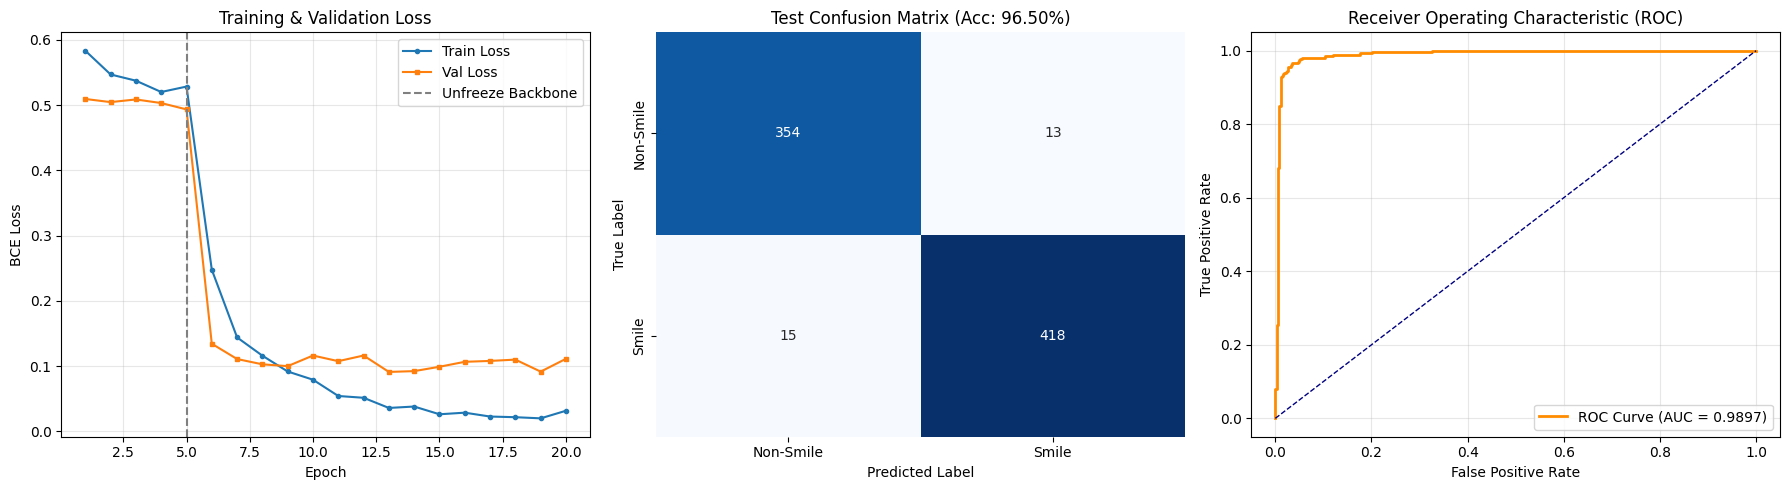

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    roc_curve
)

# 1. Load best model weights saved during training
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()

# 2. Run inference on the unseen Test set (800 images)
all_targets = []
all_probs = []
all_preds = []

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device, non_blocking=True)
        logits = model(images)
        probs = torch.sigmoid(logits).cpu().numpy()
        preds = (probs >= 0.5).astype(int)
        
        all_targets.extend(targets.numpy().astype(int))
        all_probs.extend(probs)
        all_preds.extend(preds)

all_targets = np.array(all_targets)
all_probs = np.array(all_probs)
all_preds = np.array(all_preds)

# 3. Print quantitative evaluation metrics
test_acc = accuracy_score(all_targets, all_preds)
roc_auc = roc_auc_score(all_targets, all_probs)

print(f"==========================================")
print(f"Final Test Accuracy : {test_acc * 100:.2f}%")
print(f"Final Test ROC-AUC  : {roc_auc:.4f}")
print(f"==========================================\n")
print("Detailed Classification Report:")
print(classification_report(all_targets, all_preds, target_names=["Non-Smile (0)", "Smile (1)"], digits=4))

# 4. Plot Training Curves, Confusion Matrix, and ROC Curve
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Loss & Accuracy History
epochs_range = range(1, len(history["train_loss"]) + 1)
axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", marker="o", markersize=3)
axes[0].plot(epochs_range, history["val_loss"], label="Val Loss", marker="s", markersize=3)
axes[0].axvline(x=STAGE1_EPOCHS, color="gray", linestyle="--", label="Unfreeze Backbone")
axes[0].set_title("Training & Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Subplot 2: Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
    xticklabels=["Non-Smile", "Smile"],
    yticklabels=["Non-Smile", "Smile"]
)
axes[1].set_title(f"Test Confusion Matrix (Acc: {test_acc*100:.2f}%)")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

# Subplot 3: ROC Curve
fpr, tpr, _ = roc_curve(all_targets, all_probs)
axes[2].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC Curve (AUC = {roc_auc:.4f})")
axes[2].plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--")
axes[2].set_title("Receiver Operating Characteristic (ROC)")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/evaluation_results.png", dpi=150)
plt.show()

In [8]:
import zipfile
from IPython.display import FileLink

files_to_zip = [
    "/kaggle/working/best_smile_model.pth",
    "/kaggle/working/evaluation_results.png",
    "/kaggle/working/alignment_comparison.png"
]

with zipfile.ZipFile("/kaggle/working/project_outputs.zip", "w") as zf:
    for f in files_to_zip:
        zf.write(f, arcname=f.split("/")[-1])

FileLink(r"project_outputs.zip")

/kaggle/working/project_outputs.zip